In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../figures", exist_ok=True)

RAW_DATA_PATH = "../data/raw/BDKR81DT/BDKR81FL.DTA"

print("=== COHORT ATTRITION REPORT ===")
# Reading with categorical conversion to preserve the text labels (e.g., 'Poorest', 'Urban')
df_raw = pd.read_stata(RAW_DATA_PATH, convert_categoricals=True)
count_initial = len(df_raw)
print(f"1. Total initial records in BDKR81FL.DTA (Children's Recode): {count_initial}")

# Filter for valid recent deliveries (Drop rows where m17 / C-section status is missing)
df_valid = df_raw.dropna(subset=['m17']).copy()
count_recent = len(df_valid)
print(f"2. Records remaining after isolating recent deliveries (m17 not null): {count_recent}")
print(f"   -> Dropped {count_initial - count_recent} records (older births / missing outcome)")

# Map DHS codes to readable feature names
column_mapping = {
    'm17': 'c_section',          # Target
    'v012': 'mothers_age',       # Mother's age
    'v106': 'education',         # Highest educational level
    'v190': 'wealth_index',      # Wealth index quintile
    'v025': 'residence_type',    # Urban/Rural
    'v024': 'region',            # Geographic division
    'm14': 'anc_visits',         # Prenatal checkups
    'm15': 'delivery_place',     # Type of hospital/clinic
    'bord': 'birth_order'        # Parity
}

# Ensure columns exist before filtering
available_cols = {k: v for k, v in column_mapping.items() if k in df_valid.columns}
df_clean = df_valid[list(available_cols.keys())].rename(columns=available_cols)

# Convert the target variable into binary for ML algorithms (1 = C-Section, 0 = Vaginal)
df_clean['c_section'] = df_clean['c_section'].apply(
    lambda x: 1 if str(x).strip().lower() == 'yes' else 0
)

=== COHORT ATTRITION REPORT ===
1. Total initial records in BDKR81FL.DTA (Children's Recode): 8784
2. Records remaining after isolating recent deliveries (m17 not null): 5331
   -> Dropped 3453 records (older births / missing outcome)


In [2]:
# 1. Group delivery places into clean standard categories
def categorize_delivery_place(val):
    val_str = str(val).lower()
    if 'home' in val_str or 'respondent' in val_str:
        return 'Home'
    elif 'private' in val_str or 'clinic' in val_str:
        return 'Private Facility'
    elif 'public' in val_str or 'gov' in val_str or 'hospital' in val_str or 'upazila' in val_str:
        return 'Public Facility'
    return 'Other/Unknown'

df_clean['delivery_facility_group'] = df_clean['delivery_place'].apply(categorize_delivery_place)
df_clean = df_clean.drop(columns=['delivery_place'])

# 2. Check and clean special survey missing values (e.g., 98, 99 in anc_visits)
df_clean['anc_visits'] = pd.to_numeric(df_clean['anc_visits'], errors='coerce')
# Replace 'don't know' codes with strict NaN. WE DO NOT IMPUTE THE MEDIAN HERE TO AVOID DATA LEAKAGE.
df_clean['anc_visits'] = df_clean['anc_visits'].apply(lambda x: np.nan if x > 40 else x)

# 3. Drop rows with missing values ONLY in the core demographic features
demographic_cols = ['c_section', 'mothers_age', 'education', 'wealth_index', 'residence_type', 'region', 'delivery_facility_group', 'birth_order']
df_clean = df_clean.dropna(subset=demographic_cols)

count_final = len(df_clean)
print(f"3. Records remaining after removing missing demographic values: {count_final}")
print(f"   -> Dropped {count_recent - count_final} records")
print(f"\nFINAL ANALYTIC COHORT SIZE: {count_final}")

print("\nSummary of delivery facilities:")
print(df_clean['delivery_facility_group'].value_counts())

3. Records remaining after removing missing demographic values: 5331
   -> Dropped 0 records

FINAL ANALYTIC COHORT SIZE: 5331

Summary of delivery facilities:
delivery_facility_group
Private Facility    2504
Home                1923
Public Facility      723
Other/Unknown        181
Name: count, dtype: int64


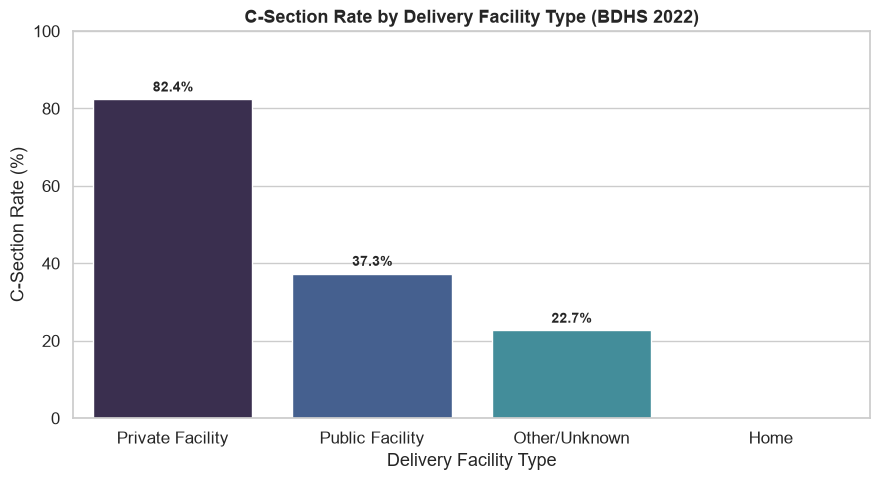

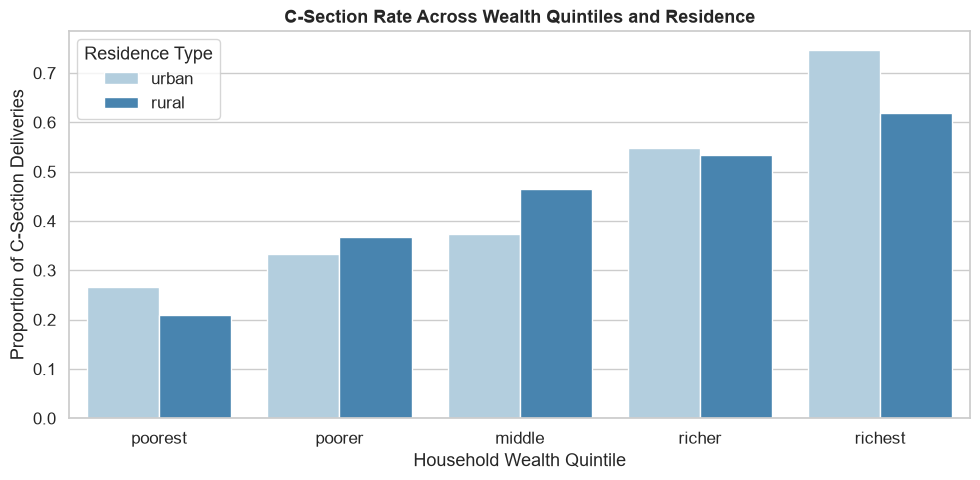

findfont: Failed to find font weight 500, now using 400.


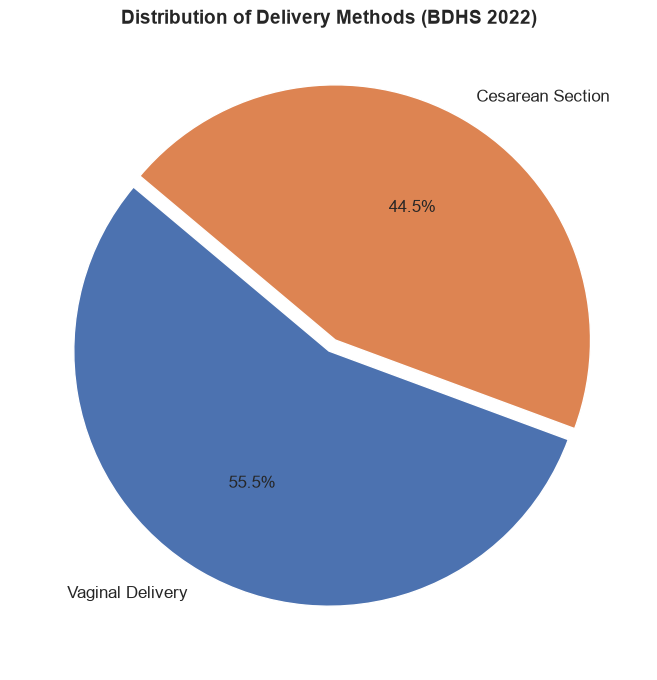

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)

# FIX: Ensure c_section is explicitly cast to a standard numeric integer type, 
# overriding the Stata categorical wrapper that prevents .mean() calculations.
df_clean['c_section'] = df_clean['c_section'].astype(int)

# Figure 1: C-Section Rate by Delivery Facility Type
plt.figure(figsize=(9, 5))
facility_rates = df_clean.groupby('delivery_facility_group')['c_section'].mean().reset_index()
facility_rates['c_section_pct'] = facility_rates['c_section'] * 100

ax1 = sns.barplot(
    data=facility_rates.sort_values(by='c_section_pct', ascending=False),
    x='delivery_facility_group', y='c_section_pct', hue='delivery_facility_group', palette='mako', legend=False
)
plt.title("C-Section Rate by Delivery Facility Type (BDHS 2022)", fontsize=13, weight='bold')
plt.ylabel("C-Section Rate (%)")
plt.xlabel("Delivery Facility Type")
plt.ylim(0, 100)

# Ignore empty bars (NaN heights) created by the 'hue' grouping
for p in ax1.patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        ax1.annotate(f"{height:.1f}%", (p.get_x() + p.get_width() / 2., height + 2),
                     ha='center', va='baseline', fontsize=10, weight='bold')
        
plt.tight_layout()
plt.savefig("../figures/fig1_facility_csection_rate.png", dpi=300)
plt.show()

# Figure 2: C-Section Disparity Across Wealth Quintiles & Residence
plt.figure(figsize=(10, 5))
wealth_order = ['poorest', 'poorer', 'middle', 'richer', 'richest']

# Cast the categorical Stata variable to a string before applying .str.lower()
df_clean['wealth_index_lower'] = df_clean['wealth_index'].astype(str).str.lower()

ax2 = sns.barplot(
    data=df_clean, x='wealth_index_lower', y='c_section', hue='residence_type',
    order=wealth_order, errorbar=None, palette='Blues'
)
plt.title("C-Section Rate Across Wealth Quintiles and Residence", fontsize=13, weight='bold')
plt.ylabel("Proportion of C-Section Deliveries")
plt.xlabel("Household Wealth Quintile")
plt.legend(title="Residence Type")
plt.tight_layout()
plt.savefig("../figures/fig2_wealth_residence_trends.png", dpi=300)
plt.show()

# Figure 3: Class Distribution
plt.figure(figsize=(7, 7))
class_counts = df_clean['c_section'].value_counts()
label_map = {0: 'Vaginal Delivery', 1: 'Cesarean Section'}
labels = [label_map[idx] for idx in class_counts.index]

plt.pie(
    class_counts, labels=labels, autopct='%1.1f%%', startangle=140, 
    colors=['#4C72B0', '#DD8452'], explode=(0, 0.05), shadow=False,
    textprops={'fontsize': 12, 'weight': '500'}
)
plt.title("Distribution of Delivery Methods (BDHS 2022)", fontsize=14, weight='bold')
plt.tight_layout()
plt.savefig("../figures/fig3_class_distribution.png", dpi=300)
plt.show()

# Drop the temporary lowercase column used for plotting
df_clean = df_clean.drop(columns=['wealth_index_lower'])

In [4]:
# 1. Define the categorical columns to encode
categorical_cols = [
    'education', 
    'wealth_index', 
    'residence_type', 
    'region', 
    'delivery_facility_group'
]

# 2. Apply One-Hot Encoding
# drop_first=True prevents the dummy variable trap required for Logistic Regression
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

# Ensure all boolean columns outputted by get_dummies are converted to 1s and 0s
for col in df_encoded.columns:
    if df_encoded[col].dtype == bool:
        df_encoded[col] = df_encoded[col].astype(int)

# 3. Save the dataset
df_encoded.to_csv("../data/processed/bdhs_2022_encoded.csv", index=False)

print(f"Fully Encoded Dataset Shape: {df_encoded.shape}")
print("CRITICAL NOTE: 'anc_visits' still contains NaN values. These will be dynamically imputed using a Scikit-Learn Pipeline during CV to prevent test-data leakage.")
display(df_encoded.head(3))

Fully Encoded Dataset Shape: (5331, 22)
CRITICAL NOTE: 'anc_visits' still contains NaN values. These will be dynamically imputed using a Scikit-Learn Pipeline during CV to prevent test-data leakage.


,c_section,mothers_age,anc_visits,birth_order,education_primary,education_secondary,education_higher,wealth_index_poorer,wealth_index_middle,wealth_index_richer,...,region_chattogram,region_dhaka,region_khulna,region_mymensingh,region_rajshahi,region_rangpur,region_sylhet,delivery_facility_group_Other/Unknown,delivery_facility_group_Private Facility,delivery_facility_group_Public Facility
0,1,37,9.0,3,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,1,0
1,1,19,3.0,1,0,1,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
3,1,30,5.0,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [5]:
import os
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

# 1. Load Data
df = pd.read_csv("../data/processed/bdhs_2022_encoded.csv")
X = df.drop('c_section', axis=1)
y = df['c_section']

# 2. Split Data (Stratified 80/20)
# Train size = 80%, Test size = 20%, Random Seed = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("=== DATA LEAKAGE PREVENTION & NaN CHECK ===")
print(f"Missing 'anc_visits' in Training Set BEFORE imputation: {X_train['anc_visits'].isna().sum()}")
print(f"Missing 'anc_visits' in Test Set BEFORE imputation: {X_test['anc_visits'].isna().sum()}")
print("These will be imputed dynamically within the CV pipeline using strictly the training median.\n")

# 3. Setup Preprocessing Pipeline
# SimpleImputer dynamically fills NaNs (like in anc_visits) using the training fold's median
preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

os.makedirs("../src/models", exist_ok=True)

# 4. Setup 10-Fold Cross Validation
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Define Models and Hyperparameter Grids
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42), 
        {'classifier__C': [0.1, 1.0, 10.0]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42), 
        {'classifier__n_estimators': [100, 200], 'classifier__max_depth': [10, None]}
    ),
    "SVM": (
        SVC(probability=True, random_state=42), 
        {'classifier__C': [0.1, 1.0], 'classifier__kernel': ['linear', 'rbf']}
    ),
    "XGBoost": (
        XGBClassifier(eval_metric='logloss', random_state=42), 
        {'classifier__n_estimators': [100, 200], 'classifier__learning_rate': [0.05, 0.1], 'classifier__max_depth': [3, 5]}
    ),
    "LightGBM": (
        LGBMClassifier(random_state=42, verbose=-1), 
        {'classifier__n_estimators': [100, 200], 'classifier__learning_rate': [0.05, 0.1], 'classifier__max_depth': [3, 5]}
    ),
    "CatBoost": (
        CatBoostClassifier(random_state=42, verbose=0), 
        {'classifier__iterations': [100, 200], 'classifier__learning_rate': [0.05, 0.1], 'classifier__depth': [4, 6]}
    )
}

# 6. Grid Search & Training Loop
best_pipelines = {}
best_classifiers = {} 
results = []
best_params_dict = {}

print("Starting 10-Fold CV Grid Search WITH Leakage-Free Pipelines...\n")
print("-" * 60)

for name, (model, params) in models.items():
    print(f"Tuning and Training: {name}...")
    
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    grid = GridSearchCV(pipeline, params, cv=cv, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train)
    
    best_pipe = grid.best_estimator_
    best_pipelines[name] = best_pipe
    best_classifiers[name] = best_pipe.named_steps['classifier']
    
    # Extract and print best hyperparameters (cleaning up the 'classifier__' prefix for readability)
    clean_params = {k.replace('classifier__', ''): v for k, v in grid.best_params_.items()}
    best_params_dict[name] = clean_params
    print(f"  -> Best Parameters: {clean_params}")
    
    joblib.dump(best_pipe, f"../src/models/{name.replace(' ', '_').lower()}_pipeline.pkl")
    
    y_pred = best_pipe.predict(X_test)
    y_prob = best_pipe.predict_proba(X_test)[:, 1]
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# 7. Stack Ensemble (Meta-Model)
print("\nTraining Stacked Ensemble...")
estimators = [(name, pipe) for name, pipe in best_pipelines.items()]
# To avoid meta-model leakage, cross_val_predict generates out-of-fold predictions
stacked_model = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(), cv=cv, n_jobs=-1)

stacked_model.fit(X_train, y_train)
y_pred_stack = stacked_model.predict(X_test)
y_prob_stack = stacked_model.predict_proba(X_test)[:, 1]

results.append({
    "Model": "Stacked Ensemble",
    "Accuracy": accuracy_score(y_test, y_pred_stack),
    "Precision": precision_score(y_test, y_pred_stack),
    "Recall": recall_score(y_test, y_pred_stack),
    "F1-Score": f1_score(y_test, y_pred_stack),
    "ROC-AUC": roc_auc_score(y_test, y_prob_stack)
})

joblib.dump(stacked_model, "../src/models/stacked_ensemble.pkl")

# 8. Transform Data for SHAP & Save Metrics
fitted_preprocessor = best_pipelines["CatBoost"].named_steps['preprocessor']
X_test_shap = pd.DataFrame(fitted_preprocessor.transform(X_test), columns=X_test.columns)
X_train_shap = pd.DataFrame(fitted_preprocessor.transform(X_train), columns=X_train.columns)

print("\n=== POST-PIPELINE NaN CHECK ===")
print(f"Missing 'anc_visits' in Training Set AFTER imputation: {X_train_shap['anc_visits'].isna().sum()}")
print(f"Missing 'anc_visits' in Test Set AFTER imputation: {X_test_shap['anc_visits'].isna().sum()}")

results_df = pd.DataFrame(results)
print("\nFinal Evaluation Results (Test Set):")
display(results_df)
results_df.to_csv("../data/processed/model_full_cv_results.csv", index=False)
print("\nSuccess! Leakage-free pipelines have been trained and saved.")

=== DATA LEAKAGE PREVENTION & NaN CHECK ===
Missing 'anc_visits' in Training Set BEFORE imputation: 527
Missing 'anc_visits' in Test Set BEFORE imputation: 153
These will be imputed dynamically within the CV pipeline using strictly the training median.

Starting 10-Fold CV Grid Search WITH Leakage-Free Pipelines...

------------------------------------------------------------
Tuning and Training: Logistic Regression...
  -> Best Parameters: {'C': 0.1}
Tuning and Training: Random Forest...
  -> Best Parameters: {'max_depth': 10, 'n_estimators': 100}
Tuning and Training: SVM...
  -> Best Parameters: {'C': 1.0, 'kernel': 'rbf'}
Tuning and Training: XGBoost...
  -> Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Tuning and Training: LightGBM...
  -> Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Tuning and Training: CatBoost...
  -> Best Parameters: {'depth': 6, 'iterations': 100, 'learning_rate': 0.1}

Training Stacked Ensemble.

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.860356,0.815891,0.886316,0.849647,0.931422
1,Random Forest,0.861293,0.826347,0.871579,0.848361,0.927205
2,SVM,0.863168,0.818182,0.890526,0.852823,0.908353
3,XGBoost,0.865042,0.826430,0.882105,0.853360,0.932669
4,LightGBM,0.864105,0.824803,0.882105,0.852492,0.932841
5,CatBoost,0.860356,0.815891,0.886316,0.849647,0.931590
6,Stacked Ensemble,0.856607,0.820717,0.867368,0.843398,0.933709



Success! Leakage-free pipelines have been trained and saved.


In [6]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix
import shap
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# 1. Create new folders for the final, leakage-free results
FINAL_FIG_DIR = "../figures/final_results"
SHAP_DIR = f"{FINAL_FIG_DIR}/shap"
os.makedirs(FINAL_FIG_DIR, exist_ok=True)
os.makedirs(SHAP_DIR, exist_ok=True)

# Combine pipelines and stacked model into a single dictionary for easy iteration
models_to_plot = {**best_pipelines, "Stacked Ensemble": stacked_model}

# ==========================================
# PART 1: Unified ROC AUC Curves
# ==========================================
print("Generating Final ROC AUC Curves...")
plt.figure(figsize=(10, 8))

for name, model in models_to_plot.items():
    # Pass the RAW X_test to the pipeline/stacked model (it handles the scaling internally)
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    
    # Highlight the Stacked Ensemble and CatBoost
    if name == "Stacked Ensemble":
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})', linewidth=2.5, color='black')
    elif name == "CatBoost":
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})', linewidth=2.5, linestyle='--', color='#DD8452')
    else:
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})', linewidth=1.5, alpha=0.6)

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, weight='bold')
plt.ylabel('True Positive Rate', fontsize=12, weight='bold')
plt.title('Receiver Operating Characteristic (ROC) Curves (Leakage-Free)', fontsize=14, weight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()

roc_path = f"{FINAL_FIG_DIR}/fig5_roc_curves_final.png"
plt.savefig(roc_path, dpi=300)
plt.close()
print(f" -> Saved: {roc_path}")

# ==========================================
# PART 2: Confusion Matrix Grid
# ==========================================
print("Generating Final Confusion Matrices...")
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
axes = axes.flatten()

for idx, (name, model) in enumerate(models_to_plot.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Vaginal', 'C-Section'], 
                yticklabels=['Vaginal', 'C-Section'],
                annot_kws={"size": 12, "weight": "bold"})
    
    axes[idx].set_title(f'{name}', fontsize=12, weight='bold')
    axes[idx].set_ylabel('Actual Label')
    axes[idx].set_xlabel('Predicted Label')

# Hide the last two empty subplots
for i in range(7, 9):
    fig.delaxes(axes[i])

plt.tight_layout()
cm_path = f"{FINAL_FIG_DIR}/fig6_confusion_matrices_final.png"
plt.savefig(cm_path, dpi=300)
plt.close()
print(f" -> Saved: {cm_path}")

# ==========================================
# PART 3: Universal SHAP Analysis
# ==========================================
print("\nGenerating Final SHAP Plots (Using Transformed Features)...")

# We must use the pre-transformed data for SHAP so the explainers understand the scaled numeric values
X_test_shap = pd.DataFrame(best_pipelines["CatBoost"].named_steps['preprocessor'].transform(X_test), columns=X_test.columns)
X_train_shap = pd.DataFrame(best_pipelines["CatBoost"].named_steps['preprocessor'].transform(X_train), columns=X_train.columns)

# Background dataset for KernelExplainer to prevent crashing
background_summary = shap.kmeans(X_train_shap, 10)
X_test_sampled = X_test_shap.sample(100, random_state=42)

for name in models_to_plot.keys():
    print(f" -> Processing SHAP for: {name}")
    try:
        if name == "Stacked Ensemble":
            # Stacked model expects raw data, not scaled data
            raw_bg = shap.kmeans(X_train, 10)
            raw_test_sampled = X_test.sample(100, random_state=42)
            
            def predict_fn_stack(X):
                return stacked_model.predict_proba(X)[:, 1]
            
            explainer = shap.KernelExplainer(predict_fn_stack, raw_bg)
            shap_values_to_plot = explainer.shap_values(raw_test_sampled, silent=True)
            data_to_plot = raw_test_sampled

        else:
            # Extract the raw trained classifier from the pipeline
            raw_model = best_pipelines[name].named_steps['classifier']
            data_to_plot = X_test_shap

            if name in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]:
                explainer = shap.TreeExplainer(raw_model)
                shap_values = explainer.shap_values(data_to_plot)
                
                # Handle varying SHAP output formats across different library versions
                if isinstance(shap_values, list):
                    shap_values_to_plot = shap_values[1]
                elif len(np.shape(shap_values)) == 3:
                    shap_values_to_plot = shap_values[:, :, 1]
                else:
                    shap_values_to_plot = shap_values

            elif name == "Logistic Regression":
                explainer = shap.LinearExplainer(raw_model, X_train_shap)
                shap_values_to_plot = explainer.shap_values(data_to_plot)

            elif name == "SVM":
                def predict_fn_svm(X):
                    return raw_model.predict_proba(X)[:, 1]
                explainer = shap.KernelExplainer(predict_fn_svm, background_summary)
                shap_values_to_plot = explainer.shap_values(X_test_sampled, silent=True)
                data_to_plot = X_test_sampled

        # Plot A: Global Feature Importance (Bar Plot)
        plt.figure(figsize=(9, 5))
        plt.title(f"SHAP Feature Importance: {name}", fontsize=12, weight='bold')
        shap.summary_plot(shap_values_to_plot, data_to_plot, plot_type="bar", show=False, color='#4C72B0')
        plt.tight_layout()
        plt.savefig(f"{SHAP_DIR}/{name.replace(' ', '_').lower()}_bar.png", dpi=300, bbox_inches='tight')
        plt.close()

        # Plot B: Summary Beeswarm Plot
        plt.figure(figsize=(9, 5))
        plt.title(f"SHAP Summary (Beeswarm): {name}", fontsize=12, weight='bold')
        shap.summary_plot(shap_values_to_plot, data_to_plot, show=False, cmap='magma')
        plt.tight_layout()
        plt.savefig(f"{SHAP_DIR}/{name.replace(' ', '_').lower()}_swarm.png", dpi=300, bbox_inches='tight')
        plt.close()

    except Exception as e:
        print(f"    [!] Error generating SHAP for {name}: {str(e)}")

print("\nSUCCESS! All updated figures have been saved to the '../figures/final_results' directory.")

Generating Final ROC AUC Curves...
 -> Saved: ../figures/final_results/fig5_roc_curves_final.png
Generating Final Confusion Matrices...


Background dataset has 4264 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4264 when initializing the masker.


 -> Saved: ../figures/final_results/fig6_confusion_matrices_final.png

Generating Final SHAP Plots (Using Transformed Features)...
 -> Processing SHAP for: Logistic Regression
 -> Processing SHAP for: Random Forest
 -> Processing SHAP for: SVM
 -> Processing SHAP for: XGBoost
 -> Processing SHAP for: LightGBM
 -> Processing SHAP for: CatBoost
 -> Processing SHAP for: Stacked Ensemble

SUCCESS! All updated figures have been saved to the '../figures/final_results' directory.


In [7]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# 1. Identify and drop the facility columns from the training and testing sets
facility_cols = [c for c in X_train.columns if 'delivery_facility' in c]
X_train_sens = X_train.drop(columns=facility_cols)
X_test_sens = X_test.drop(columns=facility_cols)

print(f"Dropped columns for Sensitivity Test: {facility_cols}\n")

# 2. Setup the strict, leakage-free pipeline using XGBoost's optimal hyperparameters
pipeline_sens_xgb = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, eval_metric='logloss', random_state=42))
])

# 3. Train the model without facility data
print("Training XGBoost Sensitivity Model (No Facility Data)...")
pipeline_sens_xgb.fit(X_train_sens, y_train)

# 4. Predict on the test set
y_pred_sens = pipeline_sens_xgb.predict(X_test_sens)
y_prob_sens = pipeline_sens_xgb.predict_proba(X_test_sens)[:, 1]

# 5. Evaluate and Print Results
print("\n=== XGBOOST SENSITIVITY TEST RESULTS (NO FACILITY DATA) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_sens):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_sens):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_sens):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_sens):.4f}")
print(f"ROC AUC:   {roc_auc_score(y_test, y_prob_sens):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_sens))

Dropped columns for Sensitivity Test: ['delivery_facility_group_Other/Unknown', 'delivery_facility_group_Private Facility', 'delivery_facility_group_Public Facility']

Training XGBoost Sensitivity Model (No Facility Data)...

=== XGBOOST SENSITIVITY TEST RESULTS (NO FACILITY DATA) ===
Accuracy:  0.6917
Precision: 0.6921
Recall:    0.5537
F1-Score:  0.6152
ROC AUC:   0.7446

Confusion Matrix:
[[475 117]
 [212 263]]


Generating Waterfall Plot for Test Patient Index: 5
Actual Label (0=Vaginal, 1=C-Section): 1
Predicted Probability: 0.8279


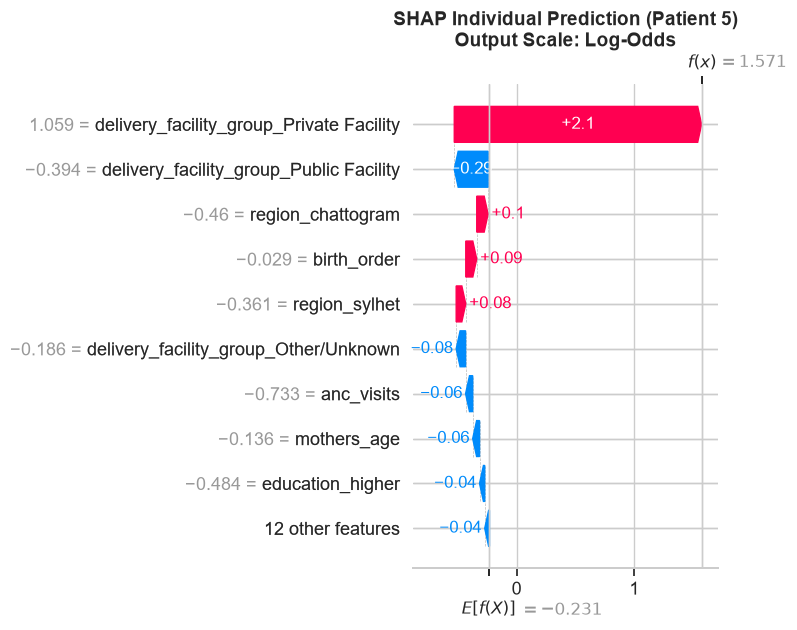

 -> Saved: ../figures/final_results/fig6_shap_waterfall_xgboost.png


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import shap
import numpy as np

# 1. Extract the fully trained XGBoost model and preprocessor from the dictionary
xgb_pipeline = best_pipelines["XGBoost"]
xgb_model = xgb_pipeline.named_steps['classifier']
preprocessor = xgb_pipeline.named_steps['preprocessor']

# 2. Transform the test data so SHAP can read the numeric values
X_test_shap = pd.DataFrame(preprocessor.transform(X_test), columns=X_test.columns)

# 3. Initialize the TreeExplainer for XGBoost
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_shap)

# 4. Select a specific patient for the example (Patient index 5)
# (Ensure this patient had a C-section to make the explanation clear)
patient_idx = 5
print(f"Generating Waterfall Plot for Test Patient Index: {patient_idx}")
print(f"Actual Label (0=Vaginal, 1=C-Section): {y_test.iloc[patient_idx]}")
print(f"Predicted Probability: {xgb_pipeline.predict_proba(X_test.iloc[[patient_idx]])[0][1]:.4f}")

# 5. Generate and save the Waterfall Plot
plt.figure(figsize=(10, 6))
# XGBoost outputs log-odds by default in SHAP; we plot those directly as the model's raw output scale
shap.plots.waterfall(shap_values[patient_idx], show=False)

plt.title(f"SHAP Individual Prediction (Patient {patient_idx})\nOutput Scale: Log-Odds", fontsize=14, weight='bold')
plt.tight_layout()
waterfall_path = "../figures/final_results/fig6_shap_waterfall_xgboost.png"
plt.savefig(waterfall_path, dpi=300, bbox_inches='tight')
plt.show()

print(f" -> Saved: {waterfall_path}")